# Task 1 – Baseline: Classical Lexical Retrieve-and-Extract

**Project 10 · Open-Domain Question Answering: From Lexical Retrieval to RAG**
**Dataset:** [`rag-datasets/rag-mini-wikipedia`](https://huggingface.co/datasets/rag-datasets/rag-mini-wikipedia)  
**Group:** 28  
**Name:** Nihar Ranjan Das  
**Roll.No:** 26AI60R20

### Objective
Build a fully classical, non-neural open-domain QA pipeline: retrieve passages with BM25 and answer by extracting a span from the retrieved text, without any text generation. This is the baseline that Task 2 (RAG) and Task 3 (hybrid retrieval) are compared against.

### Pipeline
1. **Retrieval:** BM25 (`rank_bm25`, k1 = 1.5, b = 0.75) over the full passage corpus, top-k = 5.
2. **Answering:** in the top-retrieved passage, select the sentence with the highest lexical overlap with the question, then extract the longest noun phrase or number span from that sentence.
3. **Evaluation:** Exact Match and token F1 (SQuAD-style normalisation), and Recall@k for k ∈ {1, 3, 5, 10}.

### How to run
`Runtime → Run all`. A CPU runtime is enough (about 2–3 minutes).
With `USE_DRIVE = True` (Section 1) the results are written to Google Drive, so the Task 2 and Task 3 notebooks can read them. With `USE_DRIVE = False`, or if Drive access is declined, they are written to `outputs/` and have to be downloaded.
Output files: `task1_results.json` (rankings, predictions, metrics) and `task1_recall.png`.
Project run order: **Task 1 → Task 2 → Task 3**.

### Contents
1. Setup
2. Loading the data
3. Evaluation helpers
4. A first look at the data
5. Retrieval with BM25
6. Extractive answering
7. Evaluation
8. Error analysis
9. Additional experiment: skipping spans that repeat the question
10. Recall@k plot and example predictions
11. Saving the results
12. Discussion
13. References

## 1. Setup
We install the libraries that are not pre-installed on Colab and pin the versions that affect the results (`rank_bm25` and the spaCy model), so that a re-run reproduces our numbers. The random seeds are fixed for the example table in Section 10.

All settings required by the project brief are defined once in this cell:

| Setting | Value | Meaning |
|---|---|---|
| `BM25_K1`, `BM25_B` | 1.5, 0.75 | BM25 term-frequency saturation and length normalisation |
| `TOP_K` | 5 | retrieval depth |
| `KS` | 1, 3, 5, 10 | cut-offs for Recall@k |
| `KEEP_N` | 100 | length of the saved ranking (needed for Recall@10 and for the fusion in Task 3) |
| `DATASET_REVISION` | `1f9f3b5…` | fixed version of the dataset, identical in all three notebooks |

In [1]:
# Pinned versions so Colab and local runs give identical results
%pip install -q datasets rank_bm25==0.2.2 "spacy>=3.8,<3.9" scikit-learn
%pip install -q https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl

import os, re, sys, json, string, collections, random, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42); np.random.seed(42)          # reproducibility

# Save outputs to Google Drive (Colab) so the next notebooks can read them
USE_DRIVE = False           # False = no Google Drive (results stay in the local outputs/ folder)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:        # running locally instead of Colab
    IN_COLAB = False
OUT = 'outputs'
if IN_COLAB and USE_DRIVE:
    try:
        drive.mount('/content/drive')
        OUT = '/content/drive/MyDrive/NLP_Project_2/outputs'
    except Exception as e:                   # e.g. authorisation declined or timed out
        print('Google Drive not mounted, using local outputs/ instead:', e)
os.makedirs(OUT, exist_ok=True)
print('Saving results to', OUT)

# Hyper-parameters required by the brief
BM25_K1, BM25_B = 1.5, 0.75
TOP_K = 5                  # retrieval depth used by the reader
KS = [1, 3, 5, 10]         # Recall@k values to report
KEEP_N = 100               # length of saved ranking (Recall@10 + RRF fusion in Task 3)
DATASET_REVISION = '1f9f3b53fbc5995b85aab8e993504ad42c5f16f6'   # pinned dataset version (same in all notebooks)

Saving results to outputs


## 2. Loading the data
The dataset has two configurations, and we load both:
- `text-corpus`: 3,200 Wikipedia passages, which form our retrieval index;
- `question-answer`: 918 questions with gold answers, used for all evaluation.

The passages are indexed exactly as provided, with no re-chunking. The same list, in the same order, is used in Tasks 2 and 3, and rankings are stored as positions in this list.

**Encoding repair.** While inspecting the corpus we noticed that 483 passages contain mis-encoded characters: UTF-8 text that was decoded as Latin-1, for example `Lincolnâ\x80\x99s` instead of *Lincoln’s*, or `RÃ\xado de la Plata` instead of *Río de la Plata*. Because the gold answers are clean, these passages could never match them. We therefore reverse the wrong decoding when loading the data (`fix_mojibake`). This only corrects characters: the number, order and boundaries of the passages are unchanged, and the questions and answers need no repair.

In [2]:
from datasets import load_dataset

corpus = load_dataset('rag-datasets/rag-mini-wikipedia', 'text-corpus', revision=DATASET_REVISION)
qa     = load_dataset('rag-datasets/rag-mini-wikipedia', 'question-answer', revision=DATASET_REVISION)
print(corpus)
print(qa)

def fix_mojibake(s):
    # the dataset has UTF-8 text decoded as Latin-1, e.g. 'Lincolnâ\x80\x99s' instead of 'Lincoln’s'
    try:
        return s.encode('latin-1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s                             # already clean - keep as is

raw_passages = [str(p) for p in corpus['passages']['passage']]
passages    = [fix_mojibake(p) for p in raw_passages]
passage_ids = list(corpus['passages']['id'])  # saved with the rankings, which are list positions
questions   = [fix_mojibake(str(q)) for q in qa['test']['question']]
answers     = [fix_mojibake(str(a)) for a in qa['test']['answer']]

print(len(passages), 'passages |', len(questions), 'questions')
print('passages repaired (mojibake):', sum(p != r for p, r in zip(passages, raw_passages)))
print('Example Q:', questions[0], '->', answers[0])

README.md:   0%|          | 0.00/719 [00:00<?, ?B/s]

data/passages.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B /  797kB            

data/passages.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating passages split: 0 examples [00:00, ? examples/s]

data/test.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B / 54.4kB            

data/test.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    passages: Dataset({
        features: ['passage', 'id'],
        num_rows: 3200
    })
})
DatasetDict({
    test: Dataset({
        features: ['question', 'answer', 'id'],
        num_rows: 918
    })
})
3200 passages | 918 questions
passages repaired (mojibake): 483
Example Q: Was Abraham Lincoln the sixteenth President of the United States? -> yes


## 3. Evaluation helpers
The same helper code is used in all three notebooks, so the results of Tasks 1–3 are directly comparable.

- **Normalisation (SQuAD-style):** lowercase, remove punctuation, remove the articles *a/an/the*, collapse whitespace. We remove Unicode punctuation as well as ASCII (e.g. ’ – “ ”), because the repaired passages contain typographic quotes and dashes.
- **Exact Match (EM):** 1 if the normalised prediction equals the normalised gold answer, otherwise 0.
- **Token F1:** harmonic mean of token-level precision and recall between the prediction and the gold answer.
- **Recall@k:** the dataset does not say which passage contains the answer. Following the answer-string convention used for DPR, a question counts as a hit if its normalised gold answer appears as whole words in at least one of the top-k passages. Passages are normalised once and cached, and we compute the rank of the first hit, which gives Recall@k for every k in one pass.
- **Yes/no answers:** a gold answer counts as yes/no if its first word is *yes* or *no* (this also covers answers such as *"Yes, they do."*). We report the metrics on all questions and on the non-yes/no subset.

The last line of the cell is a small sanity check of the helpers.

In [3]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP

# every Unicode punctuation / symbol character (string.punctuation plus ’ – “ ” © ° ...), built once
PUNCT_TABLE = dict.fromkeys(i for i in range(sys.maxunicode + 1)
                            if unicodedata.category(chr(i))[0] in 'PS')

def normalize_answer(s):
    # SQuAD-style: lowercase, drop punctuation, drop articles (a/an/the), squash spaces
    s = str(s).lower().translate(PUNCT_TABLE)
    s = re.sub(r'\b(a|an|the)\b', ' ', s)
    return ' '.join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    same = sum((collections.Counter(p) & collections.Counter(g)).values())
    if same == 0:
        return 0.0
    precision, recall = same / len(p), same / len(g)
    return 2 * precision * recall / (precision + recall)

norm_passages = [f' {normalize_answer(p)} ' for p in passages]   # normalised once, reused below

def answer_in_passage(gold, passage):
    # True if the normalised gold answer appears as whole words inside the passage
    g = normalize_answer(gold)
    return len(g) > 0 and f' {g} ' in f' {normalize_answer(passage)} '

def first_hit_rank(ids, gold):
    # 1-based rank of the first passage in ids that contains the gold answer (inf if none)
    g = normalize_answer(gold)
    if not g:
        return np.inf
    return next((r for r, pid in enumerate(ids, 1) if f' {g} ' in norm_passages[pid]), np.inf)

def recall_at_k(ranked_lists, golds, k):
    # ranked_lists[i] = passage positions for question i, best first
    return float(np.mean([first_hit_rank(ids[:k], g) <= k for ids, g in zip(ranked_lists, golds)]))

def content_words(text):
    # normalised words that are NOT stop words (used for overlap heuristics)
    return {w for w in normalize_answer(text).split() if w not in STOP}

def is_yes_no(ans):
    # gold answer is a yes/no answer: 'yes', 'No!', and also 'Yes, they do.' / 'No, it contributed ...'
    return normalize_answer(ans).split()[:1] in (['yes'], ['no'])

# --- sanity test: should print 1.0  0.667  True  True
print(exact_match('The Eiffel Tower!', 'eiffel tower'),
      round(f1_score('Paris 1889', '1889'), 3),
      answer_in_passage('1889', 'It was built in 1889.'),
      exact_match('Lincoln’s', "Lincoln's"))

1.0 0.667 True 1.0


## 4. A first look at the data
Before building the pipeline we check what the answers look like, because an extractive system can only return text that literally occurs in a passage.

In [4]:
n_yes_no = sum(is_yes_no(a) for a in answers)
ans_len = pd.Series([len(normalize_answer(a).split()) for a in answers])
in_corpus = np.mean([any(f' {normalize_answer(a)} ' in p for p in norm_passages) for a in answers])

print(f'yes/no answers           : {n_yes_no} / {len(answers)} ({n_yes_no/len(answers):.1%})')
print(f'gold answer length (words): mean {ans_len.mean():.2f}, median {ans_len.median():.0f}, max {ans_len.max()}')
print(f'gold answer string found somewhere in corpus: {in_corpus:.1%}  (upper bound for Recall@k)')
print(f'duplicate questions      : {len(questions) - len(set(questions))}')

yes/no answers           : 420 / 918 (45.8%)
gold answer length (words): mean 3.16, median 1, max 58
gold answer string found somewhere in corpus: 86.4%  (upper bound for Recall@k)
duplicate questions      : 0


## 5. Retrieval with BM25
### 5.1 Building the index
BM25 scores a passage by how many of the question's words it contains, weighting rare words more and normalising for passage length.

We tokenise by lower-casing and splitting on every non-word character, so *"Lincoln's"* becomes `lincoln`, `s` and *"11-year-old"* becomes `11`, `year`, `old`. Otherwise possessives and hyphenated words would never match. The index is built once over all 3,200 passages with k1 = 1.5 and b = 0.75.

In [5]:
from rank_bm25 import BM25Okapi

def tokenize(text):
    # split on any non-word character: "Lincoln's" -> lincoln, s and "11-year-old" -> 11, year, old
    return re.findall(r'\w+', str(text).lower())

tokenized_corpus = [tokenize(p) for p in tqdm(passages, desc='tokenising')]
bm25 = BM25Okapi(tokenized_corpus, k1=BM25_K1, b=BM25_B)
print('BM25 index built over', len(tokenized_corpus), 'passages')

tokenising:   0%|          | 0/3200 [00:00<?, ?it/s]

BM25 index built over 3200 passages


### 5.2 Ranking the passages for each question
For every question we score all passages and sort them by score. We keep the top 100, because Recall@10 needs 10 and Task 3 fuses longer lists; the reader only uses the top passage.

We use a stable sort on the negated scores, so passages with equal scores always keep their corpus order and the ranking is the same on every machine.

In [6]:
def bm25_search(question, k=KEEP_N):
    scores = bm25.get_scores(tokenize(question))
    top = np.argsort(-scores, kind='stable')[:k]   # highest score first; ties keep corpus order
    return [int(i) for i in top]                # plain ints so JSON can save them

t0 = time.time()
bm25_ranked = [bm25_search(q) for q in tqdm(questions, desc='BM25 search')]
print(f'retrieval time: {time.time() - t0:.1f}s  ({(time.time() - t0) / len(questions) * 1000:.1f} ms/question)')

# Look at one example
i = 0
print('Q:', questions[i], '| gold:', answers[i])
for rank, pid in enumerate(bm25_ranked[i][:TOP_K], 1):
    print(rank, passages[pid][:150].replace('\n', ' '), '...')

BM25 search:   0%|          | 0/918 [00:00<?, ?it/s]

retrieval time: 17.0s  (18.5 ms/question)
Q: Was Abraham Lincoln the sixteenth President of the United States? | gold: yes
1 Abraham Lincoln (February 12, 1809 – April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861 until his assassinat ...
2 Photograph showing the March 4, 1861, inauguration of Abraham Lincoln in front of United States Capitol. ...
3 Lincoln appointed the following Justices to the Supreme Court of the United States: ...
4 On April 9, 1865, Lee surrendered at Appomattox Court House in Virginia, and the war was effectively over. The other rebel armies surrendered soon aft ...
5 Gerald Rudolph Ford, Jr. (July 14, 1913   December 26, 2006) was the thirty-eighth President of the United States, serving from 1974 to 1977, and the  ...


## 6. Extractive answering
### 6.1 Choosing the best sentence
The top-ranked passage is split into sentences with spaCy (`en_core_web_sm`). Each sentence is scored by the number of content words (words that are not stop-words) it shares with the question, and the highest-scoring sentence is kept; ties go to the earlier sentence.

We keep the sentence as a spaCy span, so the next step can reuse its parse instead of parsing the text again.

In [7]:
import importlib, spacy
from importlib.metadata import version
try:
    nlp = spacy.load('en_core_web_sm')         # installed in Section 1
except OSError:                                # missing: download it, then import the package directly
    spacy.cli.download('en_core_web_sm')
    importlib.invalidate_caches()
    import en_core_web_sm
    nlp = en_core_web_sm.load()
print('versions: numpy', np.__version__, '| rank_bm25', version('rank_bm25'),
      '| spaCy', spacy.__version__, '| en_core_web_sm', nlp.meta['version'])

def best_sentence(question, passage):
    # returns the spaCy sentence Span, so its noun chunks / entities are reused without re-parsing
    doc = nlp(passage)
    sents = [s for s in doc.sents if s.text.strip()] or [doc[:]]
    q_words = content_words(question)
    return max(sents, key=lambda s: len(q_words & content_words(s.text)))   # ties -> first sentence

versions: numpy 2.4.6 | rank_bm25 0.2.2 | spaCy 3.8.18 | en_core_web_sm 3.8.0


### 6.2 Extracting the answer span
From the chosen sentence we collect three kinds of candidates:
- noun phrases (spaCy noun chunks);
- number-like named entities (CARDINAL, DATE, QUANTITY, MONEY, PERCENT, TIME, ORDINAL);
- single number tokens.

As the brief specifies, the answer is the longest candidate, measured in words. If a sentence has no candidates at all, we return the whole sentence.

In [8]:
NUM_LABELS = {'CARDINAL', 'DATE', 'QUANTITY', 'MONEY', 'PERCENT', 'TIME', 'ORDINAL'}

def extract_span(sent, question, skip_question_words=False):
    # sent = spaCy Span from best_sentence (parsed in the context of its passage)
    candidates  = [c.text for c in sent.noun_chunks]                     # noun phrases
    candidates += [e.text for e in sent.ents if e.label_ in NUM_LABELS] # number-like spans
    candidates += [t.text for t in sent if t.like_num]                  # single numbers
    if skip_question_words:   # extra experiment (Section 9); off for the baseline
        q_words = content_words(question)
        candidates = [c for c in candidates if not content_words(c) <= q_words] or candidates
    if not candidates:
        return sent.text.strip()                         # fallback: whole sentence
    return max(candidates, key=lambda c: len(c.split()))  # the longest span wins

def answer_task1(question, ranked_ids):
    top_passage = passages[ranked_ids[0]]               # top-retrieved passage
    sent = best_sentence(question, top_passage)
    return extract_span(sent, question), sent

t0 = time.time()
outs = [answer_task1(q, ids) for q, ids in
        tqdm(zip(questions, bm25_ranked), total=len(questions), desc='extracting')]
task1_preds = [o[0] for o in outs]
task1_spans = [o[1] for o in outs]                      # chosen sentences (spaCy Spans)
task1_sents = [s.text.strip() for s in task1_spans]
print(f'extraction time: {time.time() - t0:.1f}s')

extracting:   0%|          | 0/918 [00:00<?, ?it/s]

extraction time: 23.0s


## 7. Evaluation
We compute EM, F1 and Recall@{1, 3, 5, 10} on all 918 questions, which are the official numbers, and on the 498 questions whose answer is not yes/no.

Recall@k is only meaningful on the second subset: the words *yes* and *no* rarely appear in passages, so yes/no questions almost always count as misses.

In [9]:
def evaluate(preds, ranked, golds, name):
    row = {'System': name, 'N': len(golds),
           'EM': np.mean([exact_match(p, g) for p, g in zip(preds, golds)]),
           'F1': np.mean([f1_score(p, g) for p, g in zip(preds, golds)])}
    first = np.array([first_hit_rank(ids[:max(KS)], g) for ids, g in zip(ranked, golds)])  # once
    for k in KS:
        row[f'R@{k}'] = float(np.mean(first <= k))
    return row

keep = [i for i, a in enumerate(answers) if not is_yes_no(a)]
print('yes/no questions:', len(answers) - len(keep))

task1_table = pd.DataFrame([
    evaluate(task1_preds, bm25_ranked, answers, 'Task 1 BM25+Extract (all)'),
    evaluate([task1_preds[i] for i in keep], [bm25_ranked[i] for i in keep],
             [answers[i] for i in keep], 'Task 1 BM25+Extract (no yes/no)'),
]).round(4)
task1_table

yes/no questions: 420


,System,N,EM,F1,R@1,R@3,R@5,R@10
0,Task 1 BM25+Extract (all),918,0.0185,0.0553,0.2734,0.3333,0.3627,0.3954
1,Task 1 BM25+Extract (no yes/no),498,0.0341,0.0991,0.4900,0.5863,0.6265,0.6566


## 8. Error analysis: where are answers lost?
To find out whether retrieval or answer extraction is the weak point, we follow each question through the pipeline:
1. Is the gold answer in the top-1 passage?
2. Is it in the chosen sentence?
3. Is the extracted span exactly right?

The last row shows how often the span is right *when the answer is already in the chosen sentence*.

In [10]:
def stage_table(idx):
    top1_has = np.array([answer_in_passage(answers[i], passages[bm25_ranked[i][0]]) for i in idx])
    sent_has = np.array([answer_in_passage(answers[i], task1_sents[i]) for i in idx])
    em = np.array([exact_match(task1_preds[i], answers[i]) for i in idx])
    return {'gold in top-1 passage': top1_has.mean(),
            'gold in chosen sentence': sent_has.mean(),
            'EM (exact answer)': em.mean(),
            'EM | gold in chosen sentence': em[sent_has].mean() if sent_has.any() else np.nan}

diag = pd.DataFrame({'all': stage_table(range(len(answers))), 'no yes/no': stage_table(keep)}).round(4)
diag

,all,no yes/no
gold in top-1 passage,0.2734,0.4900
gold in chosen sentence,0.2048,0.3715
EM (exact answer),0.0185,0.0341
EM | gold in chosen sentence,0.0904,0.0919


## 9. Additional experiment: skipping spans that repeat the question
*This is an extra experiment and not part of the required baseline; the official Task 1 results are the ones in Section 7.*

The error analysis shows that the reader is the bottleneck. Looking at the predictions, the longest noun phrase is often one that simply repeats the question, for example *"John Calvin Coolidge Jr."* for *"Was John Calvin Coolidge Jr. born in Las Vegas?"*.

In this variant we discard candidate spans whose content words all appear in the question, and take the longest of the remaining ones. Retrieval is unchanged, so Recall@k is the same as for the baseline and only EM and F1 are recomputed.

In [11]:
# Re-uses the sentences chosen above (no re-parsing); only the span choice changes
variant_preds = [extract_span(span, q, skip_question_words=True)
                 for span, q in zip(task1_spans, questions)]

def with_new_answers(row, preds, golds, name):
    # same retrieval as the baseline -> copy its Recall@k, recompute only EM/F1
    return {**row, 'System': name,
            'EM': np.mean([exact_match(p, g) for p, g in zip(preds, golds)]),
            'F1': np.mean([f1_score(p, g) for p, g in zip(preds, golds)])}

variant_table = pd.DataFrame([
    task1_table.iloc[0].to_dict(), task1_table.iloc[1].to_dict(),
    with_new_answers(task1_table.iloc[0].to_dict(), variant_preds, answers,
                     'Variant: skip question words (all)'),
    with_new_answers(task1_table.iloc[1].to_dict(), [variant_preds[i] for i in keep],
                     [answers[i] for i in keep], 'Variant: skip question words (no yes/no)'),
]).round(4)
variant_table[['System', 'N', 'EM', 'F1']]

,System,N,EM,F1
0,Task 1 BM25+Extract (all),918,0.0185,0.0553
1,Task 1 BM25+Extract (no yes/no),498,0.0341,0.0991
2,Variant: skip question words (all),918,0.0512,0.0949
3,Variant: skip question words (no yes/no),498,0.0944,0.1721


## 10. Recall@k plot and example predictions
The plot shows how Recall@k grows with k, for all questions and for the non-yes/no subset. The table lists ten randomly chosen questions with the baseline and variant predictions.

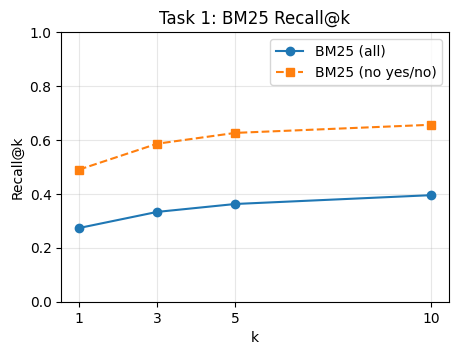

,question,gold,pred,variant,F1
0,What is polar bear's skin color?,white or cream,the world's largest land carnivores,the world's largest land carnivores,0.0
1,Is Canada a member of the OECD?,Yes.,the world's wealthiest nations,the world's wealthiest nations,0.0
2,Did Abraham Lincoln live in the Frontier?,Yes,the Abraham Lincoln Birthplace National Historic Site,the Abraham Lincoln Birthplace National Historic Site,0.0
3,When was Lee Kuan Yew prime minister of Singapore?,1959,its first Yang di-Pertuan Negara,its first Yang di-Pertuan Negara,0.0
4,What are the two subfamilies of the Native Ghanaian languages?,Kwa and Gur,the Niger-Congo language family,the Niger-Congo language family,0.0
5,What positions Ford played in the school football team?,Center and linebacker,Grand Rapids South High School,Grand Rapids South High School,0.0
6,Is the capital city Oslo?,no,the largest city,the largest city,0.0
7,Did Mainland Nova Scotia not come under British rule with the Treaty of Utre...,no!,the Seven Years' War,the Seven Years' War,0.0
8,What is the national language of Singapore?,The national language of Singapore is Malay.,The national language,the national anthem,0.5
9,Was John Calvin Coolidge Jr. was born in Las Vegas?,No,John Calvin Coolidge Jr.,the fourth of July,0.0


In [12]:
plt.figure(figsize=(5, 3.5))
plt.plot(KS, [task1_table.loc[0, f'R@{k}'] for k in KS], marker='o', label='BM25 (all)')
plt.plot(KS, [task1_table.loc[1, f'R@{k}'] for k in KS], marker='s', ls='--', label='BM25 (no yes/no)')
plt.xlabel('k'); plt.ylabel('Recall@k'); plt.title('Task 1: BM25 Recall@k')
plt.xticks(KS); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend()
plt.savefig(f'{OUT}/task1_recall.png', dpi=150, bbox_inches='tight'); plt.show()

# 10 random examples: question, gold, prediction, F1
sample = random.sample(range(len(questions)), 10)
pd.set_option('display.max_colwidth', 80)
pd.DataFrame({'question': [questions[i] for i in sample],
              'gold': [answers[i] for i in sample],
              'pred': [task1_preds[i] for i in sample],
              'variant': [variant_preds[i] for i in sample],
              'F1':   [round(f1_score(task1_preds[i], answers[i]), 2) for i in sample]})

## 11. Saving the results
We save everything that Tasks 2 and 3 need in `task1_results.json`:
- the top-100 BM25 ranking for every question;
- the baseline and variant predictions;
- the metric tables;
- the dataset ids of the ranked passages;
- the configuration, including the dataset revision, which Task 3 checks before fusing rankings.

In [13]:
with open(f'{OUT}/task1_results.json', 'w') as f:
    json.dump({'bm25_ranked': bm25_ranked,
               'preds': task1_preds,                       # required baseline (used in Task 3)
               'preds_variant': variant_preds,             # extra experiment (Section 9)
               'metrics': task1_table.to_dict(orient='records'),
               'metrics_variant': variant_table.to_dict(orient='records'),
               'passage_ids': passage_ids,                 # dataset ids of the ranked positions
               'config': {'k1': BM25_K1, 'b': BM25_B, 'top_k': TOP_K, 'keep_n': KEEP_N,
                          'dataset_revision': DATASET_REVISION}}, f)
print('saved', f'{OUT}/task1_results.json')

saved outputs/task1_results.json


## 12. Discussion

**Data.** The 918 questions are answered from 3,200 passages. 420 of them (45.8%) have a yes/no answer, including answers such as *"Yes, they do."*. The exact gold answer string occurs somewhere in the corpus for only 86.4% of the questions, and some gold answers are whole sentences of up to 58 words, which an extracted noun phrase can never match exactly.

**Retrieval.** BM25 ranks a passage containing the gold answer first for 27.3% of all questions, rising to 39.5% at k = 10. On the 498 non-yes/no questions, where answer-string recall is meaningful, recall is much higher:

| k | 1 | 3 | 5 | 10 |
|---|---|---|---|---|
| Recall@k (non-yes/no) | 49.0% | 58.6% | 62.7% | 65.7% |

Exact word matching therefore finds the evidence for about half of the factual questions. Recall keeps growing with k, so the right passage is often ranked between 2 and 10 rather than first.

**Answer extraction.** End-to-end scores are very low: EM 0.019 and F1 0.055 on all questions, and EM 0.034 and F1 0.099 on the non-yes/no questions. The error analysis shows that the bottleneck is the extraction rule rather than retrieval:
- the gold answer is inside the chosen sentence for 37.1% of the non-yes/no questions;
- but only 9.2% of those are answered exactly.

The "longest noun phrase" rule tends to pick a phrase that restates the question. Simply skipping such spans (Section 9) raises non-yes/no EM to 0.094 and F1 to 0.172. The extractive reader also cannot answer yes/no questions at all, which explains most of the gap between the "all" and "non-yes/no" rows.

**Limitations.** Recall@k is measured by answer-string matching, so short answers can match by accident and paraphrased answers are missed. EM also penalises formatting differences such as *"7"* vs *"seven"*.

**Conclusion.** A purely lexical pipeline retrieves useful evidence for roughly half of the factual questions, but the heuristic span extraction turns very little of it into exact answers. Better answer selection, rather than better retrieval, is the main room for improvement. This motivates the LLM reader in Task 2.

## 13. References
- S. Robertson and H. Zaragoza (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in Information Retrieval.
- D. Chen, A. Fisch, J. Weston and A. Bordes (2017). *Reading Wikipedia to Answer Open-Domain Questions* (DrQA). ACL.
- P. Rajpurkar, J. Zhang, K. Lopyrev and P. Liang (2016). *SQuAD: 100,000+ Questions for Machine Comprehension of Text.* EMNLP. (EM/F1 and answer normalisation)
- V. Karpukhin et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering.* EMNLP. (answer-string Recall@k)
- Tools: [`rank_bm25`](https://github.com/dorianbrown/rank_bm25), [spaCy](https://spacy.io), [Hugging Face Datasets](https://huggingface.co/docs/datasets).